# RAG Pipelines- Data Ingestion to Data Retrieval

In [1]:
import os
from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader, PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pathlib import Path

C:\Users\SAKSHAM RAJ\AppData\Local\Temp\ipykernel_2436\3712246158.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader, PyMuPDFLoader


## 1. Data Ingestion Pipeline to VectorStore

### a) Data Ingestion

In [3]:
# Read all the pdf's inside the directory

def process_all_pdfs(pdf_directory):
    """Process all PDF files in a directory"""
    all_documents = []
    pdf_dir = Path(pdf_directory)
    
    # Find all PDF files recursively
    pdf_files = list(pdf_dir.glob("**/*.pdf"))
    
    print(f"Found {len(pdf_files)} PDF files to process.")
    
    for pdf_file in pdf_files:
        print(f"\nProcessing: {pdf_file.name}")
        try:
            loader = PyPDFLoader(str(pdf_file))
            documents = loader.load()
            
            # Add source information to metadata
            for doc in documents:
                doc.metadata['source_file'] = pdf_file.name
                doc.metadata['file_type'] = 'pdf'
            
            all_documents.extend(documents)
            print(f"  ✓ Loaded {len(documents)} pages")
            
        except Exception as e:
            print(f"  ✗ Error: {e}")
    
    print(f"\nTotal documents loaded: {len(all_documents)}")
    return all_documents

# Process all PDFs in the data directory
all_pdf_documents = process_all_pdfs("../data")

Found 4 PDF files to process.

Processing: attention.pdf
  ✓ Loaded 18 pages

Processing: embeddings.pdf
  ✓ Loaded 8 pages

Processing: objectdetection.pdf
  ✓ Loaded 21 pages

Processing: proposal.pdf
  ✓ Loaded 36 pages

Total documents loaded: 83


In [6]:
all_pdf_documents 

[Document(metadata={'producer': 'Acrobat Distiller 8.1.0 (Windows)', 'creator': 'Arbortext Advanced Print Publisher 11.0.3433/W Unicode', 'creationdate': '2021-01-20T00:00:16+05:30', 'moddate': '2021-01-20T00:07:07+05:30', 'title': 'HIHC_A_1874741 1..15', 'source': '..\\data\\pdf_files\\attention.pdf', 'total_pages': 18, 'page': 0, 'page_label': '1', 'source_file': 'attention.pdf', 'file_type': 'pdf'}, page_content='HIHC #10.1080/10447318.2021.1874741, VOL 00, ISS 00\nAttention: Theory, Principles, Models and Applications\nChristopher Wickens\nQUERY SHEET\nThis page lists questions we have about your paper. The numbers displayed at left are hyperlinked to the location of the query\nin your paper.\nThe title and author names are listed on this sheet as they will be published, both on your paper and on the Table of Contents.\nPlease review and ensure the information is correct and advise us if any changes need to be made. In addition, please review\nyour paper as a whole for typographica

### b) Chunking

In [7]:
# Text splitting get into chunks

def split_documents(documents,chunk_size=1000,chunk_overlap=200):
    """Split documents into smaller chunks for better RAG performance"""
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        length_function=len,
        separators=["\n\n", "\n", " ", ""]
    )
    split_docs = text_splitter.split_documents(documents)
    print(f"Split {len(documents)} documents into {len(split_docs)} chunks")
    
    # Show example of a chunk
    if split_docs:
        print(f"\nExample chunk:")
        print(f"Content: {split_docs[0].page_content[:200]}...")
        print(f"Metadata: {split_docs[0].metadata}")
    
    return split_docs

In [8]:
chunks=split_documents(all_pdf_documents)
chunks

Split 83 documents into 462 chunks

Example chunk:
Content: HIHC #10.1080/10447318.2021.1874741, VOL 00, ISS 00
Attention: Theory, Principles, Models and Applications
Christopher Wickens
QUERY SHEET
This page lists questions we have about your paper. The numbe...
Metadata: {'producer': 'Acrobat Distiller 8.1.0 (Windows)', 'creator': 'Arbortext Advanced Print Publisher 11.0.3433/W Unicode', 'creationdate': '2021-01-20T00:00:16+05:30', 'moddate': '2021-01-20T00:07:07+05:30', 'title': 'HIHC_A_1874741 1..15', 'source': '..\\data\\pdf_files\\attention.pdf', 'total_pages': 18, 'page': 0, 'page_label': '1', 'source_file': 'attention.pdf', 'file_type': 'pdf'}


[Document(metadata={'producer': 'Acrobat Distiller 8.1.0 (Windows)', 'creator': 'Arbortext Advanced Print Publisher 11.0.3433/W Unicode', 'creationdate': '2021-01-20T00:00:16+05:30', 'moddate': '2021-01-20T00:07:07+05:30', 'title': 'HIHC_A_1874741 1..15', 'source': '..\\data\\pdf_files\\attention.pdf', 'total_pages': 18, 'page': 0, 'page_label': '1', 'source_file': 'attention.pdf', 'file_type': 'pdf'}, page_content='HIHC #10.1080/10447318.2021.1874741, VOL 00, ISS 00\nAttention: Theory, Principles, Models and Applications\nChristopher Wickens\nQUERY SHEET\nThis page lists questions we have about your paper. The numbers displayed at left are hyperlinked to the location of the query\nin your paper.\nThe title and author names are listed on this sheet as they will be published, both on your paper and on the Table of Contents.\nPlease review and ensure the information is correct and advise us if any changes need to be made. In addition, please review\nyour paper as a whole for typographica

### c) Embedding Generation

Can use any type of Models

In [10]:
import numpy as np
from sentence_transformers import SentenceTransformer
import chromadb
from chromadb.config import Settings
import uuid # to store ID of every vector
from typing import List, Dict, Any, Tuple
from sklearn.metrics.pairwise import cosine_similarity

g:\SAKSHAM RAJ\Courses\Agentic AI by Krish Naik\vectorRAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
class EmbeddingManager:
    """Handles document embedding generation using SentenceTransformer"""
    # Every class needs to have an init method to initialize the class
    def __init__(self, model_name: str = "all-MiniLM-L6-v2"):
        """
        Initialize the embedding manager
        
        Args:
            model_name: HuggingFace model name for sentence embeddings
        """
        self.model_name = model_name # text to vector model (384 dimensions)
        self.model = None
        self._load_model()

    def _load_model(self):
        """Load the SentenceTransformer model"""
        try:
            print(f"Loading embedding model: {self.model_name}")
            self.model = SentenceTransformer(self.model_name)
            print(f"Model loaded successfully. Embedding dimension: {self.model.get_embedding_dimension()}")
        except Exception as e:
            print(f"Error loading model {self.model_name}: {e}")
            raise

    def generate_embeddings(self, texts: List[str]) -> np.ndarray:
        """
        Generate embeddings for a list of texts
        
        Args:
            texts: List of text strings to embed
            
        Returns:
            numpy array of embeddings with shape (len(texts), embedding_dim)
        """
        if not self.model:
            raise ValueError("Model not loaded")
        
        print(f"Generating embeddings for {len(texts)} texts...")
        embeddings = self.model.encode(texts, show_progress_bar=True)
        print(f"Generated embeddings with shape: {embeddings.shape}")
        return embeddings


# initialize the embedding manager

embedding_manager=EmbeddingManager()
embedding_manager

Loading embedding model: all-MiniLM-L6-v2


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 248.25it/s]


Model loaded successfully. Embedding dimension: 384


### d) VectorStore DB

In [13]:
class VectorStore:
    """Manages document embeddings in a ChromaDB vector store"""
    
    def __init__(self, collection_name: str = "pdf_documents", persist_directory: str = "../data/vector_store"):
        """
        Initialize the vector store
        
        Args:
            collection_name: Name of the ChromaDB collection
            persist_directory: Directory to persist the vector store
        """
        self.collection_name = collection_name
        self.persist_directory = persist_directory
        self.client = None
        self.collection = None
        self._initialize_store()

    def _initialize_store(self):
        """Initialize ChromaDB client and collection"""
        try:
            # Create persistent ChromaDB client
            os.makedirs(self.persist_directory, exist_ok=True)
            self.client = chromadb.PersistentClient(path=self.persist_directory)
            
            # Get or create collection
            self.collection = self.client.get_or_create_collection(
                name=self.collection_name,
                metadata={"description": "PDF document embeddings for RAG"}
            )
            print(f"Vector store initialized. Collection: {self.collection_name}")
            print(f"Existing documents in collection: {self.collection.count()}")
            
        except Exception as e:
            print(f"Error initializing vector store: {e}")
            raise

    def add_documents(self, documents: List[Any], embeddings: np.ndarray):
        """
        Add documents and their embeddings to the vector store
        
        Args:
            documents: List of LangChain documents
            embeddings: Corresponding embeddings for the documents
        """
        if len(documents) != len(embeddings):
            raise ValueError("Number of documents must match number of embeddings")
        
        print(f"Adding {len(documents)} documents to vector store...")
        
        # Prepare data for ChromaDB
        ids = []
        metadatas = []
        documents_text = []
        embeddings_list = []
        
        for i, (doc, embedding) in enumerate(zip(documents, embeddings)):
            # Generate unique ID
            doc_id = f"doc_{uuid.uuid4().hex[:8]}_{i}"
            ids.append(doc_id)
            
            # Prepare metadata
            metadata = dict(doc.metadata)
            metadata['doc_index'] = i
            metadata['content_length'] = len(doc.page_content)
            metadatas.append(metadata)
            
            # Document content
            documents_text.append(doc.page_content)
            
            # Embedding
            embeddings_list.append(embedding.tolist())
        
        # Add to collection
        try:
            self.collection.add(
                ids=ids,
                embeddings=embeddings_list,
                metadatas=metadatas,
                documents=documents_text
            )
            print(f"Successfully added {len(documents)} documents to vector store")
            print(f"Total documents in collection: {self.collection.count()}")
            
        except Exception as e:
            print(f"Error adding documents to vector store: {e}")
            raise

vectorstore=VectorStore()
vectorstore

Vector store initialized. Collection: pdf_documents
Existing documents in collection: 0


In [14]:
chunks

[Document(metadata={'producer': 'Acrobat Distiller 8.1.0 (Windows)', 'creator': 'Arbortext Advanced Print Publisher 11.0.3433/W Unicode', 'creationdate': '2021-01-20T00:00:16+05:30', 'moddate': '2021-01-20T00:07:07+05:30', 'title': 'HIHC_A_1874741 1..15', 'source': '..\\data\\pdf_files\\attention.pdf', 'total_pages': 18, 'page': 0, 'page_label': '1', 'source_file': 'attention.pdf', 'file_type': 'pdf'}, page_content='HIHC #10.1080/10447318.2021.1874741, VOL 00, ISS 00\nAttention: Theory, Principles, Models and Applications\nChristopher Wickens\nQUERY SHEET\nThis page lists questions we have about your paper. The numbers displayed at left are hyperlinked to the location of the query\nin your paper.\nThe title and author names are listed on this sheet as they will be published, both on your paper and on the Table of Contents.\nPlease review and ensure the information is correct and advise us if any changes need to be made. In addition, please review\nyour paper as a whole for typographica

In [15]:
# Convert the text to embeddings
texts=[doc.page_content for doc in chunks]

# Generate the Embeddings
embeddings=embedding_manager.generate_embeddings(texts)

# store in the vector database
vectorstore.add_documents(chunks,embeddings)

Generating embeddings for 462 texts...


Batches: 100%|██████████| 15/15 [01:51<00:00,  7.41s/it]


Generated embeddings with shape: (462, 384)
Adding 462 documents to vector store...
Successfully added 462 documents to vector store
Total documents in collection: 462


## 2. RAG Retrieval Pipeline from VectorStore

In [16]:
class RAGRetriever:
    """Handles query-based retrieval from the vector store"""
    
    def __init__(self, vector_store: VectorStore, embedding_manager: EmbeddingManager):
        """
        Initialize the retriever
        
        Args:
            vector_store: Vector store containing document embeddings
            embedding_manager: Manager for generating query embeddings
        """
        self.vector_store = vector_store
        self.embedding_manager = embedding_manager

    def retrieve(self, query: str, top_k: int = 5, score_threshold: float = 0.0) -> List[Dict[str, Any]]:
        """
        Retrieve relevant documents for a query
        
        Args:
            query: The search query
            top_k: Number of top results to return
            score_threshold: Minimum similarity score threshold
            
        Returns:
            List of dictionaries containing retrieved documents and metadata
        """
        print(f"Retrieving documents for query: '{query}'")
        print(f"Top K: {top_k}, Score threshold: {score_threshold}")
        
        # Generate query embedding
        query_embedding = self.embedding_manager.generate_embeddings([query])[0]
        
        # Search in vector store
        try:
            results = self.vector_store.collection.query(
                query_embeddings=[query_embedding.tolist()],
                n_results=top_k
            )
            
            # Process results
            retrieved_docs = []
            
            if results['documents'] and results['documents'][0]:
                documents = results['documents'][0]
                metadatas = results['metadatas'][0]
                distances = results['distances'][0]
                ids = results['ids'][0]
                
                for i, (doc_id, document, metadata, distance) in enumerate(zip(ids, documents, metadatas, distances)):
                    # Convert distance to similarity score (ChromaDB uses cosine distance)
                    similarity_score = 1 - distance
                    
                    if similarity_score >= score_threshold:
                        retrieved_docs.append({
                            'id': doc_id,
                            'content': document,
                            'metadata': metadata,
                            'similarity_score': similarity_score,
                            'distance': distance,
                            'rank': i + 1
                        })
                
                print(f"Retrieved {len(retrieved_docs)} documents (after filtering)")
            else:
                print("No documents found")
            
            return retrieved_docs
            
        except Exception as e:
            print(f"Error during retrieval: {e}")
            return []

rag_retriever=RAGRetriever(vectorstore,embedding_manager)

In [17]:
rag_retriever

In [26]:
rag_retriever.retrieve("What is Attention in multi-tasking?")

Retrieving documents for query: 'What is Attention in multi-tasking?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  4.93it/s]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_50976194_12',
  'content': 'ARTICLEQ1\nAttention: Theory, Principles, Models and Applications\nChristopher WickensQ2\nAdjunct Professor Psychology, Colorado State University, Fort Collins, United States\n5 ABSTRACT\nQ3 We discuss two general concepts of attention: (1) As a filter of selective attention that selects and\nadmits channels of information from the environment to be processed; (2) as a resource to enable\nsubsequent information processing, constrained by the individual demand of tasks, and particularly the\ncollective demands of multiple tasks needing to be performed concurrently defining the limits of\n10 multitasking. In both concept domains we review theories and design principles, and particularly\ncomputational models of attentional process and performance outputs. In discussing the filter we\nconsider supervisory control, noticing, visual search, and the way in which limited selective attention\nconstrains the filter can be overcome to avail more parallel 

In [29]:
rag_retriever.retrieve("How does Object detection work in Deep Learning")

Retrieving documents for query: 'How does Object detection work in Deep Learning'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  4.49it/s]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_6d406db3_166',
  'content': 'deeper features, are introduced to address the problems existing\nin traditional architectures. These models behave differently\nin network architecture, training strategy and optimization\nfunction, etc. In this paper, we provide a review on deep\nlearning based object detection frameworks. Our review begins\nwith a brief introduction on the history of deep learning and\nits representative tool, namely Convolutional Neural Network\n(CNN). Then we focus on typical generic object detection\narchitectures along with some modiﬁcations and useful tricks\nto improve detection performance further. As distinct speciﬁc\ndetection tasks exhibit different characteristics, we also brieﬂy\nsurvey several speciﬁc tasks, including salient object detection,\nface detection and pedestrian detection. Experimental analyses\nare also provided to compare various methods and draw some\nmeaningful conclusions. Finally, several promising directions and\ntasks are pro

In [24]:
rag_retriever.retrieve("What is Embeddings to philosophy?")

Retrieving documents for query: 'What is Embeddings to philosophy?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  6.54it/s]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_1fff3485_138',
  'content': 'about the importance of context, especially for causal explanations of phenomena. For instance, \nMarxist economic historians have a theory of the ‘embeddedness’ of economic actions in social and \ncultural contexts  (K. Polanyi 1944). Economic sociologists built on those insights to argue that \neconomic actions are ‘situated’ or ‘embedded’ in networks of social connections of varying strength \nand distance (Granovetter 1973, 1985). This metaphorical approach is not how I will use the concept \nhere, however. Rather, by the concept of embedding, I refer to its formal deﬁnition and technical \nmeaning in mathematics (speciﬁcally, algebra and topology) and in computer science (speciﬁcally, \nmachine learning) as a class of mapping functions . I refer to embedding as a principle of abstract \nengineering, not of causal methodology. \nIn mathematics, an embedding refers to one mathematical structure being contained within',
  'metadata': {'conten

## 3. Data Retrieval Pipeline - VectorDB To LLM Output Generation

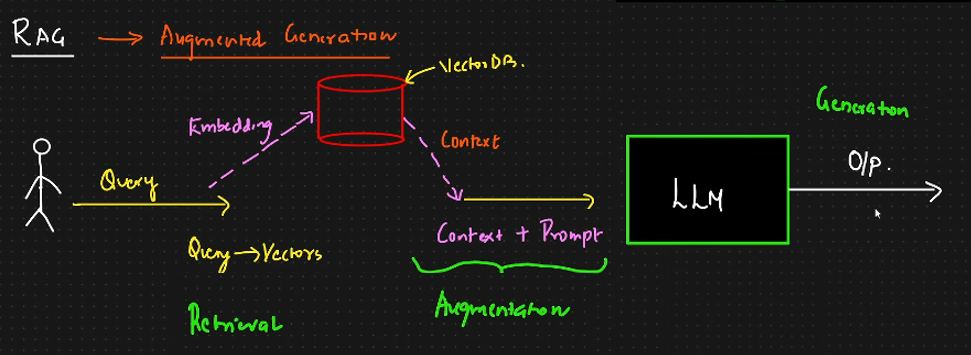

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

print(os.getenv("GROQ_API_KEY"))

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.messages import SystemMessage, HumanMessage

In [37]:
class GroqLLM:
    def __init__(self, model_name: str = "gemma2-9b-it", api_key: str =None):
        """
        Initialize Groq LLM
        
        Args:
            model_name: Groq model name (qwen2-72b-instruct, llama3-70b-8192, etc.)
            api_key: Groq API key (or set GROQ_API_KEY environment variable)
        """
        self.model_name = model_name
        self.api_key = api_key or os.environ.get("GROQ_API_KEY")
        
        if not self.api_key:
            raise ValueError("Groq API key is required. Set GROQ_API_KEY environment variable or pass api_key parameter.")
        
        self.llm = ChatGroq(
            groq_api_key=self.api_key,
            model_name=self.model_name,
            temperature=0.1,
            max_tokens=1024
        )
        
        print(f"Initialized Groq LLM with model: {self.model_name}")

    def generate_response(self, query: str, context: str, max_length: int = 500) -> str:
        """
        Generate response using retrieved context
        
        Args:
            query: User question
            context: Retrieved document context
            max_length: Maximum response length
            
        Returns:
            Generated response string
        """
        
        # Create prompt template
        prompt_template = PromptTemplate(
            input_variables=["context", "question"],
            template="""You are a helpful AI assistant. Use the following context to answer the question accurately and concisely.

Context:
{context}

Question: {question}

Answer: Provide a clear and informative answer based on the context above. If the context doesn't contain enough information to answer the question, say so."""
        )
        
        # Format the prompt
        formatted_prompt = prompt_template.format(context=context, question=query)
        
        try:
            # Generate response
            messages = [HumanMessage(content=formatted_prompt)]
            response = self.llm.invoke(messages)
            return response.content
            
        except Exception as e:
            return f"Error generating response: {str(e)}"
        
    def generate_response_simple(self, query: str, context: str) -> str:
        """
        Simple response generation without complex prompting
        
        Args:
            query: User question
            context: Retrieved context
            
        Returns:
            Generated response
        """
        simple_prompt = f"""Based on this context: {context}

Question: {query}

Answer:"""
        
        try:
            messages = [HumanMessage(content=simple_prompt)]
            response = self.llm.invoke(messages)
            return response.content
        except Exception as e:
            return f"Error: {str(e)}"

In [38]:
# Initialize Groq LLM (you'll need to set GROQ_API_KEY environment variable)
try:
    groq_llm = GroqLLM(api_key=os.getenv("GROQ_API_KEY"))
    print("Groq LLM initialized successfully!")
except ValueError as e:
    print(f"Warning: {e}")
    print("Please set your GROQ_API_KEY environment variable to use the LLM.")
    groq_llm = None

Initialized Groq LLM with model: gemma2-9b-it
Groq LLM initialized successfully!


In [40]:
# get the context from the retriever and pass it to the LLM

rag_retriever.retrieve("How Face Detection works in Deep Learning?")

Retrieving documents for query: 'How Face Detection works in Deep Learning?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  4.50it/s]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_e29aaaae_299',
  'content': 'The most famous face detector proposed by Viola and\nJones [166] trains cascaded classiﬁers with Haar-Like features\nand AdaBoost, achieving good performance with real-time\nefﬁciency. However, this detector may degrade signiﬁcantly\nin real-world applications due to larger visual variations of\nhuman faces. Different from this cascade structure, Felzen-\nszwalb et al. proposed a deformable part model (DPM) for face\ndetection [24]. However, for these traditional face detection\nmethods, high computational expenses and large quantities\nof annotations are required to achieve a reasonable result.\nBesides, their performance is greatly restricted by manually\ndesigned features and shallow architecture.\nA. Deep learning in Face Detection\nRecently, some CNN based face detection approaches have\nbeen proposed [167]–[169].As less accurate localization re-\nsults from independent regressions of object coordinates, Yu\net al. [167] proposed a novel I

#### Integration Vectordb Context pipeline With LLM output

In [ ]:
# Simple RAG pipeline with Groq LLM
from langchain_groq import ChatGroq
import os
from dotenv import load_dotenv
load_dotenv()

# Initialize the Groq LLM (set your GROQ_API_KEY in environment)
groq_api_key = os.getenv("GROQ_API_KEY")

llm=ChatGroq(groq_api_key=groq_api_key,model_name="openai/gpt-oss-20b",temperature=0.1,max_tokens=1024)

# 2. Simple RAG function: retrieve context + generate response
def rag_simple(query,retriever,llm,top_k=3):
    ## retrieve the context
    results=retriever.retrieve(query,top_k=top_k)
    context="\n\n".join([doc['content'] for doc in results]) if results else ""
    if not context:
        return "No relevant context found to answer the question."
    
    # generate the answwer using GROQ LLM
    prompt=f"""Use the following context to answer the question concisely.
        Context:
        {context}

        Question: {query}

        Answer:"""
    
    response=llm.invoke([prompt.format(context=context,query=query)])
    return response.content

In [44]:
answer=rag_simple("How Face Detection works in Deep Learning?",rag_retriever,llm)
print(answer)

Retrieving documents for query: 'How Face Detection works in Deep Learning?'
Top K: 3, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  2.42it/s]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
**Deep‑learning face detection** turns the classic “scan‑and‑classify” pipeline into a single, end‑to‑end convolutional network that learns both feature extraction and bounding‑box regression from data.

1. **Feature learning** – A CNN replaces hand‑crafted Haar or HOG features. Convolutional layers automatically learn hierarchical representations (edges → textures → facial parts) from raw pixels.

2. **Region proposal / dense prediction** – Modern detectors (e.g., Faster‑RCNN, SSD, YOLO) generate candidate boxes or predict a dense heat‑map of face locations. Some methods (ScaleFace) split the scale range into sub‑networks to handle faces from tiny to large.

3. **Bounding‑box regression** – Instead of independent coordinate regressions, recent works (Yu et al.) use an IoU‑based loss that jointly predicts the four box boundaries, improving localization accuracy.

4. **Part‑based refinement** – Networks ca

**Deep‑learning face detection** turns the classic “scan‑and‑classify” pipeline into a single, end‑to‑end convolutional network that learns both feature extraction and bounding‑box regression from data.

1. **Feature learning** – A CNN replaces hand‑crafted Haar or HOG features. Convolutional layers automatically learn hierarchical representations (edges → textures → facial parts) from raw pixels.

2. **Region proposal / dense prediction** – Modern detectors (e.g., Faster‑RCNN, SSD, YOLO) generate candidate boxes or predict a dense heat‑map of face locations. Some methods (ScaleFace) split the scale range into sub‑networks to handle faces from tiny to large.

3. **Bounding‑box regression** – Instead of independent coordinate regressions, recent works (Yu et al.) use an IoU‑based loss that jointly predicts the four box boundaries, improving localization accuracy.

4. **Part‑based refinement** – Networks can aggregate responses from local facial parts (eyes, nose, mouth) to robustly detect occluded or partially visible faces (Yang et al.).

5. **Training data & loss** – Large annotated face datasets are used. Losses combine classification (face vs. background) and regression (IoU or smooth‑L1). Some methods (DDFD) even avoid pose/landmark labels, learning multi‑view detection directly.

6. **Inference** – A single forward pass yields a set of face bounding boxes with confidence scores, achieving real‑time performance on modern GPUs.

In short, deep‑learning face detection learns end‑to‑end from pixels to face boxes, using CNN feature extraction, scale‑aware prediction, part‑based cues, and IoU‑aware regression to handle pose, occlusion, and scale variations.

In [45]:
answer=rag_simple("Generative AI such as LLMs",rag_retriever,llm)
print(answer)

Retrieving documents for query: 'Generative AI such as LLMs'
Top K: 3, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  3.19it/s]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Generative AI such as LLMs are massive neural‑network models that learn to represent language as high‑dimensional embeddings. Trained on billions of tokens, they encode cultural and sensory information—not as a database but as a distributed representation—so their “model‑ness” comes from the embedding itself rather than a simplified abstraction of reality.


Generative AI such as LLMs are massive neural‑network models that learn to represent language as high‑dimensional embeddings. Trained on billions of tokens, they encode cultural and sensory information—not as a database but as a distributed representation—so their “model‑ness” comes from the embedding itself rather than a simplified abstraction of reality.

### Enhanced RAG Pipeline Features

In [ ]:
# Enhanced RAG Pipeline Features
def rag_advanced(query, retriever, llm, top_k=5, min_score=0.2, return_context=False):
    """
    RAG pipeline with extra features:
    - Returns answer, sources, confidence score, and optionally full context.
    """
    results = retriever.retrieve(query, top_k=top_k, score_threshold=min_score)
    if not results:
        return {'answer': 'No relevant context found.', 'sources': [], 'confidence': 0.0, 'context': ''}
    
    # Prepare context and sources
    context = "\n\n".join([doc['content'] for doc in results])
    sources = [{
        'source': doc['metadata'].get('source_file', doc['metadata'].get('source', 'unknown')),
        'page': doc['metadata'].get('page', 'unknown'),
        'score': doc['similarity_score'],
        'preview': doc['content'][:300] + '...'
    } for doc in results]
    confidence = max([doc['similarity_score'] for doc in results])
    
    # Generate answer
    prompt = f"""Use the following context to answer the question concisely.\nContext:\n{context}\n\nQuestion: {query}\n\nAnswer:"""
    response = llm.invoke([prompt.format(context=context, query=query)])
    
    output = {
        'answer': response.content,
        'sources': sources,
        'confidence': confidence
    }
    if return_context:
        output['context'] = context
    return output

In [56]:
# Example usage:
result = rag_advanced("What is Attention mechanism?", rag_retriever, llm, top_k=3, min_score=0.1, return_context=True)
print("Answer:", result['answer'])
print("Sources:", result['sources'])
print("Confidence:", result['confidence'])
print("Context Preview:", result['context'][:300])

Retrieving documents for query: 'What is Attention mechanism?'
Top K: 3, Score threshold: 0.1
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00, 11.40it/s]

Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)


Answer: **Attention mechanism** is the cognitive process that selects and prioritizes relevant information from the environment and allocates the limited processing resources needed to analyze it. It acts as a filter that admits only a subset of sensory inputs into conscious awareness and as a resource manager that determines how much capacity is devoted to each concurrent task, thereby shaping perception, decision‑making, and multitasking performance.
Sources: [{'source': 'attention.pdf', 'page': 3, 'score': 0.3535783290863037, 'preview': '40 examples are the texting driver who causes a collision; or emer-\ngency management in the aircraft or at the nuclear power con-\nsole, where the operator must diagnose a problem, based upon\na cacophony of alarms and a Christmas tree of warning lights,\nand then multi-task, in order to stabilize the ...'}, {'source': 'attention.pdf', 'page': 3, 'score': 0.22607409954071045, 'preview': 'ARTICLEQ1\nAttention: Theory, Principles, Models and Applicat

In [51]:
# Example usage:
result = rag_advanced("What provides provides a general way of understanding the relation between generative AI?", rag_retriever, llm, top_k=3, min_score=0.1, return_context=True)
print("Answer:", result['answer'])
print("Sources:", result['sources'])
print("Confidence:", result['confidence'])

Retrieving documents for query: 'What provides provides a general way of understanding the relation between generative AI?'
Top K: 3, Score threshold: 0.1
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  5.76it/s]


Generated embeddings with shape: (1, 384)
Retrieved 2 documents (after filtering)
Answer: The general way to understand generative AI is to view it as a **nested embedding**: an LLM is an embedding of human language, which itself is an embedding of shared cultural experience and neural coding of sense impressions. This multi‑level embedding perspective explains how generative AI aligns with culture rather than with individual preferences.
Sources: [{'source': 'embeddings.pdf', 'page': 4, 'score': 0.21913284063339233, 'preview': 'Generative AI such as LLMs are very large matrices (i.e. the trained model, as an artiﬁcial neural \nnetwork, parameterised with billions of numerical weights). These are an embedding in digital \ncircuits of written language (the training set) but, crucially, not as a database or any kind of memory. ...'}, {'source': 'embeddings.pdf', 'page': 4, 'score': 0.1260964274406433, 'preview': 'been embedded in a new way. It is not an ‘artiﬁcial’ intelligence but an ev

In [57]:
# Example usage:
result = rag_advanced("What is New cultural science?", rag_retriever, llm, top_k=3, min_score=0.1, return_context=True)
print("Answer:", result['answer'])
print("Sources:", result['sources'])
print("Confidence:", result['confidence'])

Retrieving documents for query: 'What is New cultural science?'
Top K: 3, Score threshold: 0.1
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:01<00:00,  1.07s/it]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Answer: **New cultural science** is a research paradigm that treats large language models (LLMs) as a ready‑made, manipulable “cultural pool.” By constraining the model’s embedding space—effectively boxing it to exclude certain knowledge types—researchers can generate synthetic demes (cultures) and analyze their outputs. This approach turns LLMs into a “culturetron,” an investigative tool that lets scholars study cultural formation, alignment between machine and human intelligence, and the role of storytelling at the speed of prompts, bypassing the cost, censorship, and unpredictability of fieldwork.
Sources: [{'source': 'embeddings.pdf', 'page': 6, 'score': 0.13957160711288452, 'preview': 'the science of culture by turning these models around and using them as an investigative tool: a \nculturetron. \nWe don’t need to build a culturetron – my claim is that that new scientiﬁc tool already exists. Our \nta

#### Advanced RAG Pipeline: Streaming, Citations, History, Summarization

In [54]:
# --- Advanced RAG Pipeline: Streaming, Citations, History, Summarization ---
from typing import List, Dict, Any
import time

class AdvancedRAGPipeline:
    def __init__(self, retriever, llm):
        self.retriever = retriever
        self.llm = llm
        self.history = []  # Store query history

    def query(self, question: str, top_k: int = 5, min_score: float = 0.2, stream: bool = False, summarize: bool = False) -> Dict[str, Any]:
        # Retrieve relevant documents
        results = self.retriever.retrieve(question, top_k=top_k, score_threshold=min_score)
        if not results:
            answer = "No relevant context found."
            sources = []
            context = ""
        else:
            context = "\n\n".join([doc['content'] for doc in results])
            sources = [{
                'source': doc['metadata'].get('source_file', doc['metadata'].get('source', 'unknown')),
                'page': doc['metadata'].get('page', 'unknown'),
                'score': doc['similarity_score'],
                'preview': doc['content'][:120] + '...'
            } for doc in results]
            # Streaming answer simulation
            prompt = f"""Use the following context to answer the question concisely.\nContext:\n{context}\n\nQuestion: {question}\n\nAnswer:"""
            if stream:
                print("Streaming answer:")
                for i in range(0, len(prompt), 80):
                    print(prompt[i:i+80], end='', flush=True)
                    time.sleep(0.05)
                print()
            response = self.llm.invoke([prompt.format(context=context, question=question)])
            answer = response.content

        # Add citations to answer
        citations = [f"[{i+1}] {src['source']} (page {src['page']})" for i, src in enumerate(sources)]
        answer_with_citations = answer + "\n\nCitations:\n" + "\n".join(citations) if citations else answer

        # Optionally summarize answer
        summary = None
        if summarize and answer:
            summary_prompt = f"Summarize the following answer in 2 sentences:\n{answer}"
            summary_resp = self.llm.invoke([summary_prompt])
            summary = summary_resp.content

        # Store query history
        self.history.append({
            'question': question,
            'answer': answer,
            'sources': sources,
            'summary': summary
        })

        return {
            'question': question,
            'answer': answer_with_citations,
            'sources': sources,
            'summary': summary,
            'history': self.history
        }


In [55]:
# Example usage:
adv_rag = AdvancedRAGPipeline(rag_retriever, llm)
result = adv_rag.query("what is attention mechanism in Artificial Intelligence?", top_k=3, min_score=0.1, stream=True, summarize=True)
print("\nFinal Answer:", result['answer'])
print("Summary:", result['summary'])
print("History:", result['history'][-1])

Retrieving documents for query: 'what is attention mechanism in Artificial Intelligence?'
Top K: 3, Score threshold: 0.1
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00, 10.14it/s]

Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Streaming answer:
Use the following context to answer the question concisely.
Context:
40 examples are the texting driver who causes a collision; or emer-
gency management in the

 aircraft or at the nuclear power con-
sole, where the operator must diagnose a problem, based upon
a cacophony of alarms and a Christmas tree of warning lights,
and then multi-task, in order to stabilize the system, commu-
45 nicate and further troubleshoot.
In this article, we introduce the theories of attention from
which models and principles are derived, within the context
of a descriptive model of human attention and performance
shown in Figure 1 . Such principles, if applied in design, can
50potentially remediate problems of attention such as those
described above. On the left of the figure, multiple dynamic
events and more static sources of input in the world are
received by the human senses. In turn, this (frequently)
large number must be filtered by our selective attention,s o
55that only the limited number, within our bandwidth limita-

In concluding section B, the filter of selective attention
incorporates several different processes, whereby visual infor-
mation input is s